# Lab 1

### Setup
Load the libraries and set the random seed.

In [1]:
%pip install numpy pandas matplotlib seaborn scipy kagglehub

Note: you may need to restart the kernel to use updated packages.


### Import the data
We will use the [German Credit Data](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data)

In [2]:
import kagglehub
import pandas as pd
from os import path

# Download latest version
dataset_path = kagglehub.dataset_download("uciml/german-credit")
df = pd.read_csv(path.join(dataset_path, "german_credit_data.csv"))
print(df.head())
print(df.info())

/Users/alex/Documents/labs/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


   Unnamed: 0  Age     Sex  Job Housing Saving accounts Checking account  \
0           0   67    male    2     own             NaN           little   
1           1   22  female    2     own          little         moderate   
2           2   49    male    1     own          little              NaN   
3           3   45    male    2    free          little           little   
4           4   53    male    2    free          little           little   

   Credit amount  Duration              Purpose  
0           1169         6             radio/TV  
1           5951        48             radio/TV  
2           2096        12            education  
3           7882        42  furniture/equipment  
4           4870        24                  car  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Unnamed: 0        1000 non-null   int64 

### Define normality tests
We will use histograms, Q-Q plots and the Kolmogorov-Smirnov test

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm, probplot, kstest

def normality_tests(df, target_columns):
    print("Plotting histograms for numerical columns...")
    df[target_columns].hist(bins=15, figsize=(10, 5), layout=(1, len(target_columns)))
    plt.suptitle('Histograms of Numerical Columns')
    plt.show()

    print("Plotting Q-Q plots for numerical columns...")
    plt.figure(figsize=(10, 5))
    for i, col in enumerate(target_columns):
        plt.subplot(1, len(target_columns), i + 1)
        probplot(df[col], dist="norm", plot=plt)
        plt.title(f'Q-Q Plot of {col}')
    plt.tight_layout()
    plt.show()

    print('KSTest for normality:')
    lognorm_dataset = lognorm.rvs(s=0.5, scale=np.exp(1), size=1000)
    print(kstest(lognorm_dataset, 'norm'))

### Try to normalize the data
Try to normalize the data using different methods. Which one works best?

Plotting histograms for numerical columns...


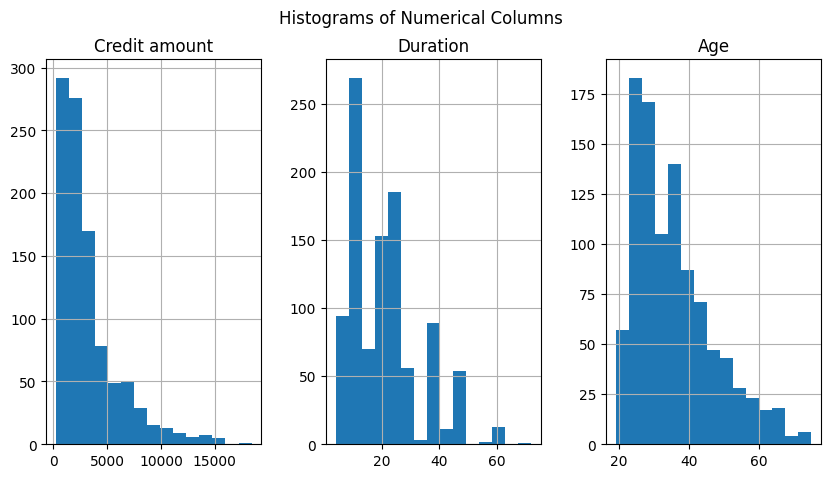

Plotting Q-Q plots for numerical columns...


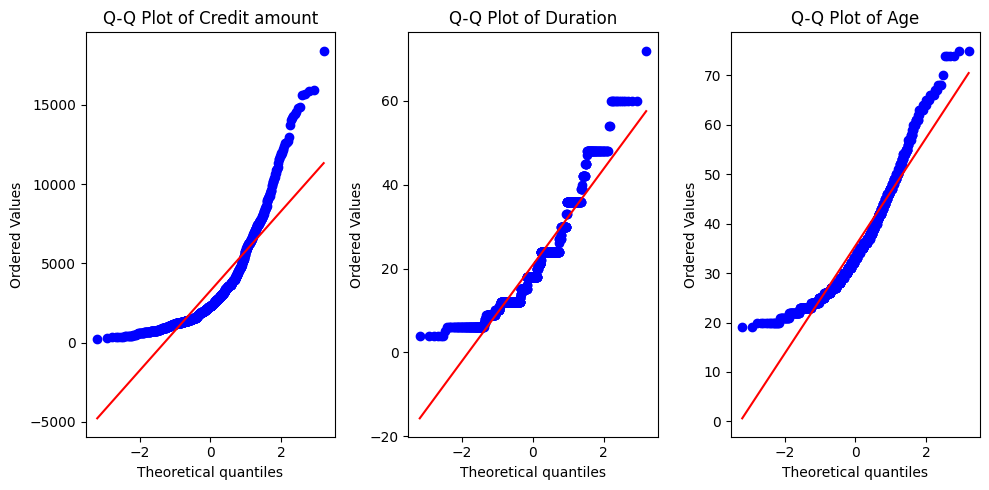

Kst test for normality:
KstestResult(statistic=np.float64(0.8369867710145271), pvalue=np.float64(0.0), statistic_location=np.float64(1.2264577694377437), statistic_sign=np.int8(-1))


In [ ]:
import numpy as np

target_columns = ['Credit amount', 'Duration', 'Age']
normality_tests(df, target_columns)

### Normalize data

Kst test results before transformation: [1.         0.99996833 1.        ]
Kst test results after log transformation: [0.99999998 0.96716723 0.99863107]
Plotting histograms for numerical columns...


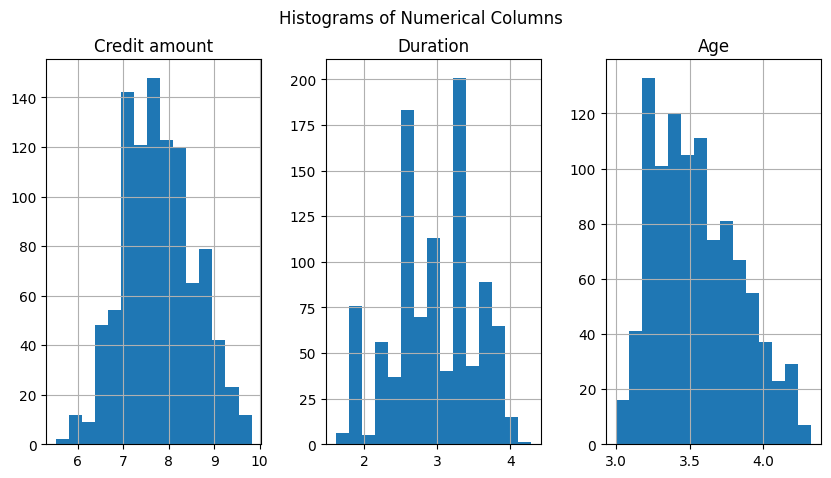

Plotting Q-Q plots for numerical columns...


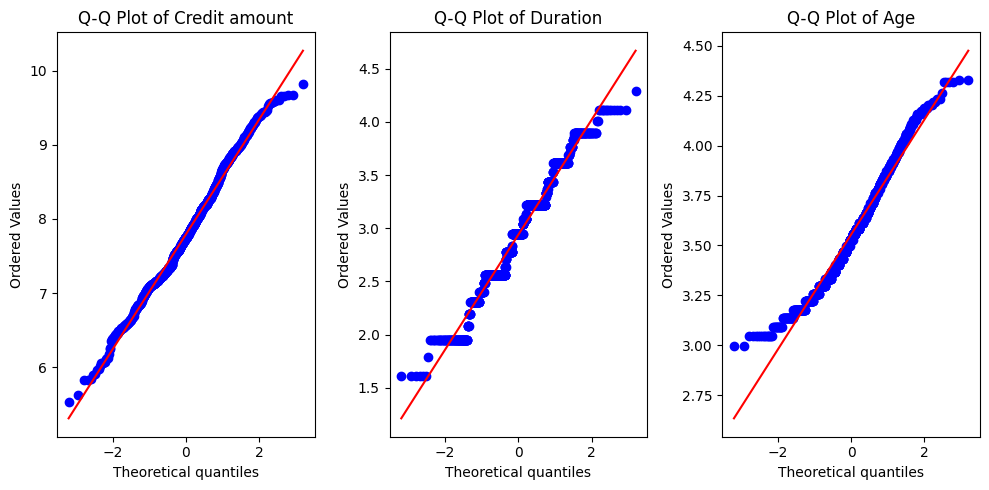

Kst test for normality:
KstestResult(statistic=np.float64(0.8361647513379481), pvalue=np.float64(0.0), statistic_location=np.float64(1.2435356909422943), statistic_sign=np.int8(-1))
Plotting histograms for numerical columns...


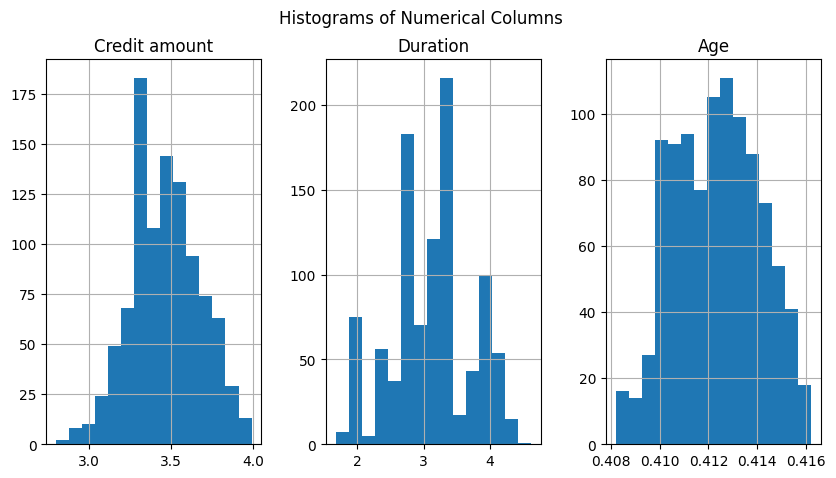

Plotting Q-Q plots for numerical columns...


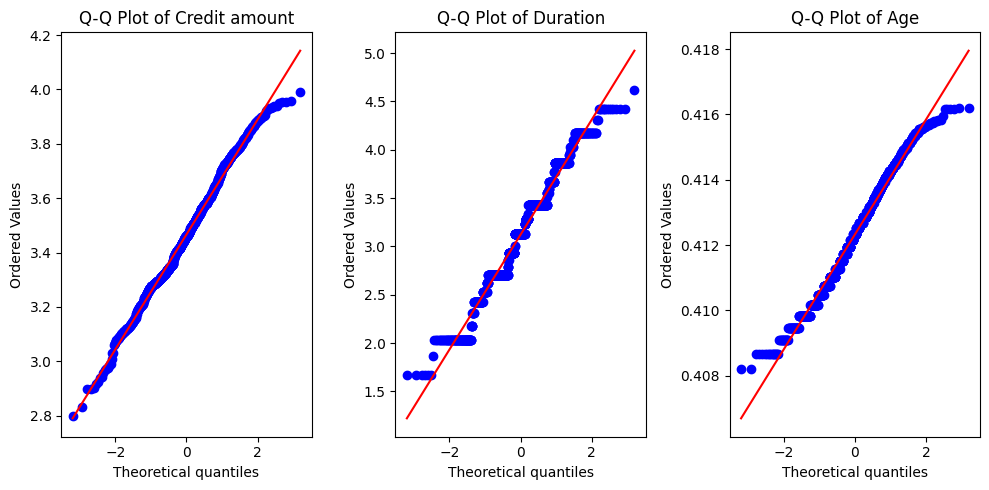

Kst test for normality:
KstestResult(statistic=np.float64(0.830066753346959), pvalue=np.float64(0.0), statistic_location=np.float64(1.2539326309906698), statistic_sign=np.int8(-1))


In [ ]:
from scipy.stats import boxcox, kstest

# Derive a new dataframe with log-transformed columns
kolmogorov_smirnov = np.array([kstest(df[col], 'norm').statistic for col in target_columns])
print(f"Kst test results before transformation: {kolmogorov_smirnov}")
df_normalized = df.copy()
df_normalized[target_columns] = df_normalized[target_columns].apply(lambda x: np.log(x + 1))
kolmogorov_smirnov = np.array([kstest(df_normalized[col], 'norm').statistic for col in target_columns])
print(f"Kst test results after log transformation: {kolmogorov_smirnov}")
normality_tests(df_normalized, target_columns)

# Use Box-Cox transformation
df_normalized[target_columns] = df_normalized[target_columns].apply(lambda x: boxcox(x + 1)[0])
normality_tests(df_normalized, target_columns)